# Get Corpus Master by merging all sources

In [29]:
#merge speeches
import csv
import pandas as pd
from pathlib import Path

REQUIRED_SOURCES = ["kormanyinfo.csv", "lazarinfo.csv", "mp_junoct.csv",
                    "mp_novdec.csv"]

EXPECTED_COLS = 21
MIN_ROWS = 194  # rows from the four M2 sources alone


def build():
    sources = list(REQUIRED_SOURCES)

    # Read files directly from the current directory
    frames = [pd.read_csv(f) for f in sources]
    df = pd.concat(frames, ignore_index=True)

    assert df.shape[1] == EXPECTED_COLS, f"col count {df.shape[1]} != {EXPECTED_COLS}"
    assert df.shape[0] >= MIN_ROWS, f"row count {df.shape[0]} < {MIN_ROWS}"
    assert df["doc_id"].is_unique, "doc_id collisions"

    df["date"] = pd.to_datetime(df["date"]).dt.strftime("%Y-%m-%d")
    df = df.sort_values(["source", "date"]).reset_index(drop=True)

    # Output directly to the current directory
    out = "all_speeches_clean.csv"
    df.to_csv(
        out, index=False, quoting=csv.QUOTE_ALL, lineterminator="\n",
        encoding="utf-8",
    )

    roundtrip = pd.read_csv(out)
    assert roundtrip.shape == df.shape
    return out, df


if __name__ == "__main__":
    out, df = build()
    print(f"wrote {out} ({df.shape})")
    print(df.groupby("source").size().to_string())

wrote all_speeches_clean.csv ((194, 21))
source
kormanyinfo      21
lazarinfo        49
magyar_peter    124


In [30]:
import re
import unicodedata

NEWSLETTER_PATTERNS = [
    r"Kövesd a Telexet a Facebookon",
    r"Ha tetszett ez a cikk",
    r"Olvass tovább",
    r"Iratkozz fel hírlevelünkre",
    r"Hírlevél felirat",
    r"Kövess minket",
]

WHITESPACE_RE = re.compile(r"\s+")
MULTIPLE_PUNCT_RE = re.compile(r"([.!?,;:])\1{2,}")
URL_RE = re.compile(r"https?://\S+")
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")


def clean_text(raw: str) -> str:
    if not isinstance(raw, str) or not raw:
        return ""
    t = unicodedata.normalize("NFKC", raw)
    for pat in NEWSLETTER_PATTERNS:
        t = re.sub(pat, " ", t, flags=re.IGNORECASE)
    t = URL_RE.sub(" ", t)
    t = EMAIL_RE.sub(" ", t)
    t = MULTIPLE_PUNCT_RE.sub(r"\1", t)
    t = WHITESPACE_RE.sub(" ", t).strip()
    return t


def n_words(s: str) -> int:
    if not isinstance(s, str) or not s:
        return 0
    return len(s.split())


def n_chars(s: str) -> int:
    if not isinstance(s, str):
        return 0
    return len(s)


def is_usable(n_words_clean: int, language: str, min_words: int = 80) -> bool:
    return bool(n_words_clean >= min_words and language == "hu")

In [31]:
import csv
import pandas as pd

EXPECTED_COLS = [
    "doc_id", "url", "source", "date", "title", "author", "language",
    "description", "text", "n_chars", "n_words", "text_clean", "text_lower",
    "n_chars_clean", "n_words_clean", "is_usable",
]


def build():
    df = pd.read_csv("telex_full.csv", encoding="utf-8")
    assert df.shape == (716, 9), f"unexpected raw shape {df.shape}"

    df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="raise")
    df["date"] = df["date"].dt.strftime("%Y-%m-%d")

    df["n_chars"] = df["text"].apply(n_chars)
    df["n_words"] = df["text"].apply(n_words)

    df["text_clean"] = df["text"].apply(clean_text)
    df["text_lower"] = df["text_clean"].str.lower()
    df["n_chars_clean"] = df["text_clean"].apply(n_chars)
    df["n_words_clean"] = df["text_clean"].apply(n_words)
    df["is_usable"] = df.apply(
        lambda r: is_usable(r["n_words_clean"], r["language"]), axis=1
    )

    df = df[EXPECTED_COLS]
    df = df.sort_values("date").reset_index(drop=True)

    out = "telex_full2.csv"
    df.to_csv(
        out, index=False, quoting=csv.QUOTE_ALL, lineterminator="\n",
        encoding="utf-8",
    )

    rt = pd.read_csv(out)
    assert rt.shape == (716, 16)
    assert rt["language"].eq("hu").all()
    return out, df


if __name__ == "__main__":
    out, df = build()
    print(f"wrote {out} ({df.shape})")
    print(f"is_usable: {df['is_usable'].sum()} / {len(df)}")
    print(f"date range: {df['date'].min()} -> {df['date'].max()}")

wrote telex_full2.csv ((716, 16))
is_usable: 695 / 716
date range: 2025-07-28 -> 2026-04-11


In [32]:
import csv
import pandas as pd

SOURCE_TYPE = {
    "kormanyinfo": "speech_government",
    "lazarinfo": "speech_government",
    "magyar_peter": "speech_opposition",
    "origo": "news_progov",
    "telex": "news_independent",
}

OUTPUT_COLS = [
    "doc_id", "source", "source_type", "date", "lang", "title", "url",
    "n_words_clean", "is_usable", "text_clean",
]


def _normalize_speech(df: pd.DataFrame) -> pd.DataFrame:
    o = pd.DataFrame()
    o["doc_id"] = df["doc_id"]
    o["source"] = df["source"]
    o["source_type"] = df["source"].map(SOURCE_TYPE)
    o["date"] = pd.to_datetime(df["date"]).dt.strftime("%Y-%m-%d")
    o["lang"] = df["language"]
    o["title"] = df["title"]
    o["url"] = df["url"]
    o["n_words_clean"] = df["n_words_clean"]
    o["is_usable"] = df["is_usable"]
    o["text_clean"] = df["transcript_clean"]
    return o


def _normalize_news(df: pd.DataFrame, source: str) -> pd.DataFrame:
    o = pd.DataFrame()
    o["doc_id"] = df["doc_id"]
    o["source"] = source
    o["source_type"] = SOURCE_TYPE[source]
    o["date"] = pd.to_datetime(df["date"]).dt.strftime("%Y-%m-%d")
    o["lang"] = df["language"]
    o["title"] = df["title"]
    o["url"] = df["url"]
    o["n_words_clean"] = df["n_words_clean"]
    o["is_usable"] = df["is_usable"]
    o["text_clean"] = df["text_clean"]
    return o


def build():
    speeches = pd.read_csv("all_speeches_clean.csv")
    telex = pd.read_csv("telex_full2.csv")
    origo = pd.read_csv("origo_articles.csv")

    n_sp, n_tx, n_or = len(speeches), len(telex), len(origo)

    parts = [
        _normalize_speech(speeches),
        _normalize_news(telex, "telex"),
        _normalize_news(origo, "origo"),
    ]
    df = pd.concat(parts, ignore_index=True)
    df = df[OUTPUT_COLS]

    assert df["doc_id"].is_unique, "doc_id collisions across sources"
    assert len(df) == n_sp + n_tx + n_or
    df = df.sort_values(["source_type", "source", "date"]).reset_index(drop=True)

    out = "corpus_master.csv"
    df.to_csv(out, index=False, quoting=csv.QUOTE_ALL, lineterminator="\n",
              encoding="utf-8")

    return out, df


if __name__ == "__main__":
    out, df = build()
    print(f"wrote {out} ({df.shape})")
    print("by source:")
    print(df.groupby(["source_type", "source"]).agg(
        docs=("doc_id", "size"),
        usable=("is_usable", "sum"),
        words=("n_words_clean", "sum"),
    ).to_string())
    print(f"\ntotal usable: {df['is_usable'].sum()}")
    print(f"date range: {df['date'].min()} -> {df['date'].max()}")

wrote corpus_master.csv ((1401, 10))
by source:
                                docs  usable    words
source_type       source                             
news_independent  telex          716     695   370904
news_progov       origo          491     476   142353
speech_government kormanyinfo     21      21    44379
                  lazarinfo       49      49   876007
speech_opposition magyar_peter   124     104  1159993

total usable: 1345
date range: 2025-06-18 -> 2026-04-12


In [33]:
# Load data
df = pd.read_csv("corpus_master.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

Shape: (1401, 10)

Columns:
Index(['doc_id', 'source', 'source_type', 'date', 'lang', 'title', 'url',
       'n_words_clean', 'is_usable', 'text_clean'],
      dtype='object')


In [34]:
# =========================
# BASIC DESCRIPTIVE STATS
# =========================

print("\nDocuments by source:")
print(df["source"].value_counts())

print("\nDocuments by source type:")
print(df["source_type"].value_counts())

print("\nWord count statistics:")
print(df["n_words_clean"].describe())

print("\nDate range:")
print(df["date"].min(), "->", df["date"].max())

print("\nMissing values:")
print(df.isna().sum())


Documents by source:
source
telex           716
origo           491
magyar_peter    124
lazarinfo        49
kormanyinfo      21
Name: count, dtype: int64

Documents by source type:
source_type
news_independent     716
news_progov          491
speech_opposition    124
speech_government     70
Name: count, dtype: int64

Word count statistics:
count     1401.000000
mean      1851.274804
std       4505.190212
min          0.000000
25%        183.000000
50%        315.000000
75%        671.000000
max      29321.000000
Name: n_words_clean, dtype: float64

Date range:
2025-06-18 -> 2026-04-12

Missing values:
doc_id            0
source            0
source_type       0
date              0
lang              0
title             0
url               0
n_words_clean     0
is_usable         0
text_clean       20
dtype: int64


PREPARE DATE COLUMN

In [35]:
df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.to_period("M").astype(str)

# GRAPH 1 — DOCUMENTS BY SOURCE

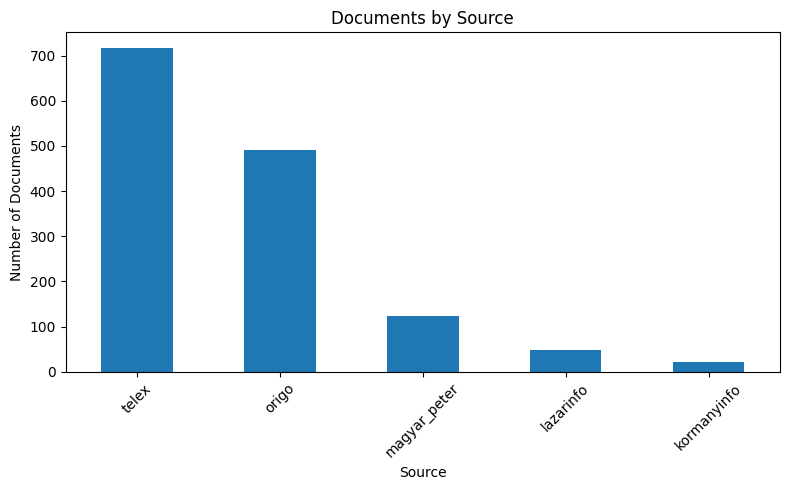

In [36]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
df["source"].value_counts().plot(kind="bar")
plt.title("Documents by Source")
plt.xlabel("Source")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# GRAPH 2 — MONTHLY DOCUMENT VOLUME

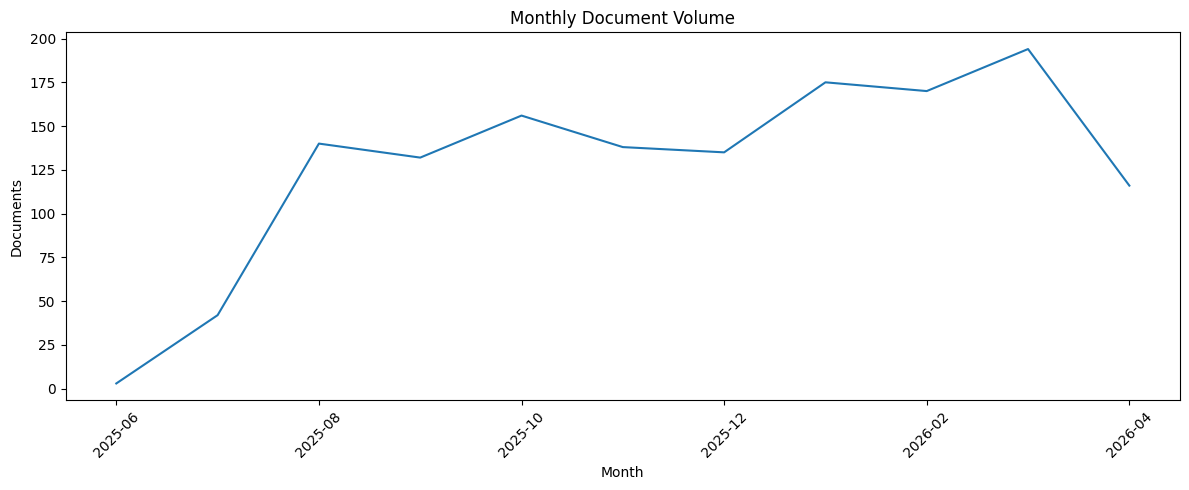

In [37]:
monthly_counts = df.groupby("month").size()

plt.figure(figsize=(12,5))
monthly_counts.plot()
plt.title("Monthly Document Volume")
plt.xlabel("Month")
plt.ylabel("Documents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# GRAPH 3 — WORD COUNT DISTRIBUTION

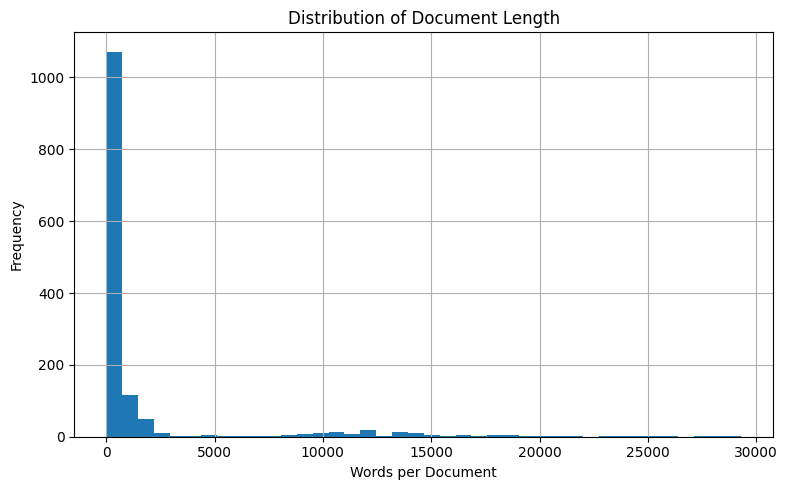

In [38]:
plt.figure(figsize=(8,5))
df["n_words_clean"].hist(bins=40)
plt.title("Distribution of Document Length")
plt.xlabel("Words per Document")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# GRAPH 4 — AVERAGE DOCUMENT LENGTH BY SOURCE

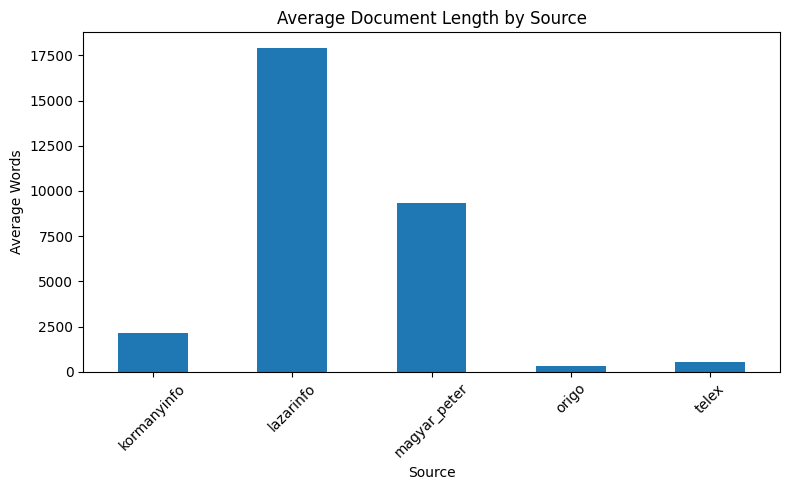

In [39]:
avg_words = df.groupby("source")["n_words_clean"].mean()

plt.figure(figsize=(8,5))
avg_words.plot(kind="bar")
plt.title("Average Document Length by Source")
plt.xlabel("Source")
plt.ylabel("Average Words")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# OPTIONAL: SUMMARY TABLE

In [40]:
summary = df.groupby("source").agg(
    documents=("doc_id", "size"),
    total_words=("n_words_clean", "sum"),
    avg_words=("n_words_clean", "mean"),
    usable_docs=("is_usable", "sum")
)

print("\nSummary Table:")
print(summary)


Summary Table:
              documents  total_words     avg_words  usable_docs
source                                                         
kormanyinfo          21        44379   2113.285714           21
lazarinfo            49       876007  17877.693878           49
magyar_peter        124      1159993   9354.782258          104
origo               491       142353    289.924644          476
telex               716       370904    518.022346          695


# 1. Corpus activity over time by source

<Figure size 1200x600 with 0 Axes>

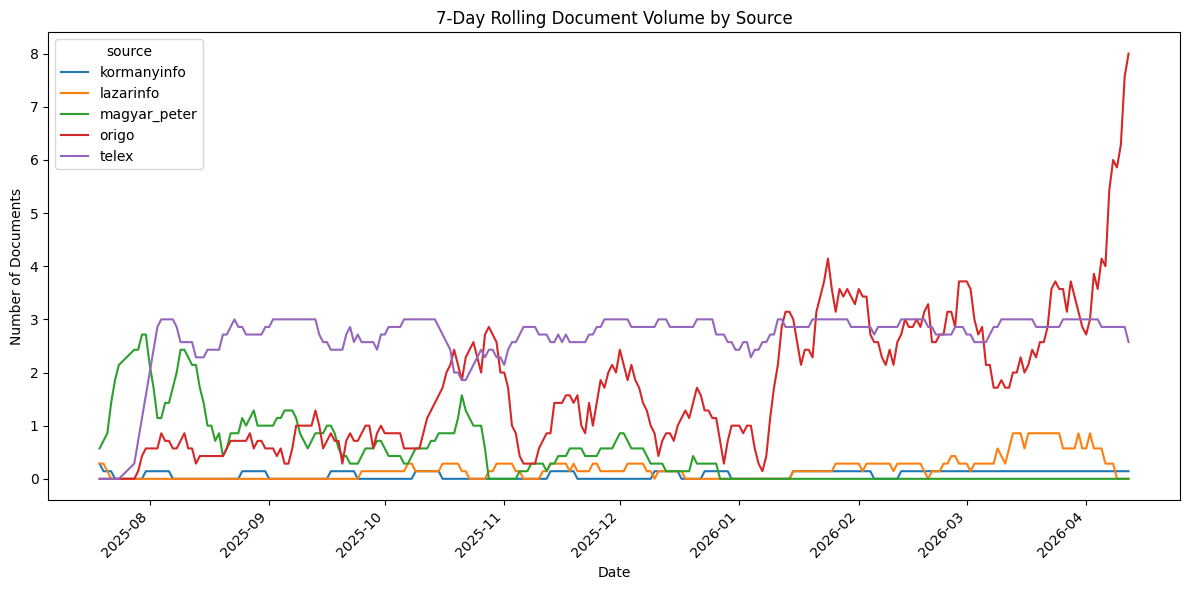

In [41]:
daily_source = (
    df.groupby(["date", "source"])
    .size()
    .reset_index(name="documents")
)

pivot_daily = daily_source.pivot(
    index="date",
    columns="source",
    values="documents"
).fillna(0)

plt.figure(figsize=(12, 6))
pivot_daily.rolling(7).mean().plot(figsize=(12, 6))

plt.title("7-Day Rolling Document Volume by Source")
plt.xlabel("Date")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Source contribution to the full corpus

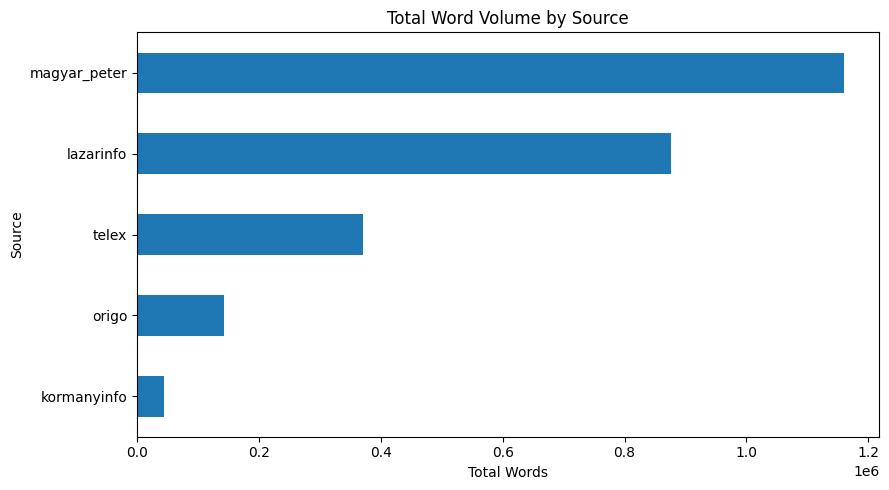

In [42]:
source_words = (
    df.groupby("source")["n_words_clean"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(9, 5))
source_words.plot(kind="barh")

plt.title("Total Word Volume by Source")
plt.xlabel("Total Words")
plt.ylabel("Source")
plt.tight_layout()
plt.show()

# 3. Monthly corpus composition

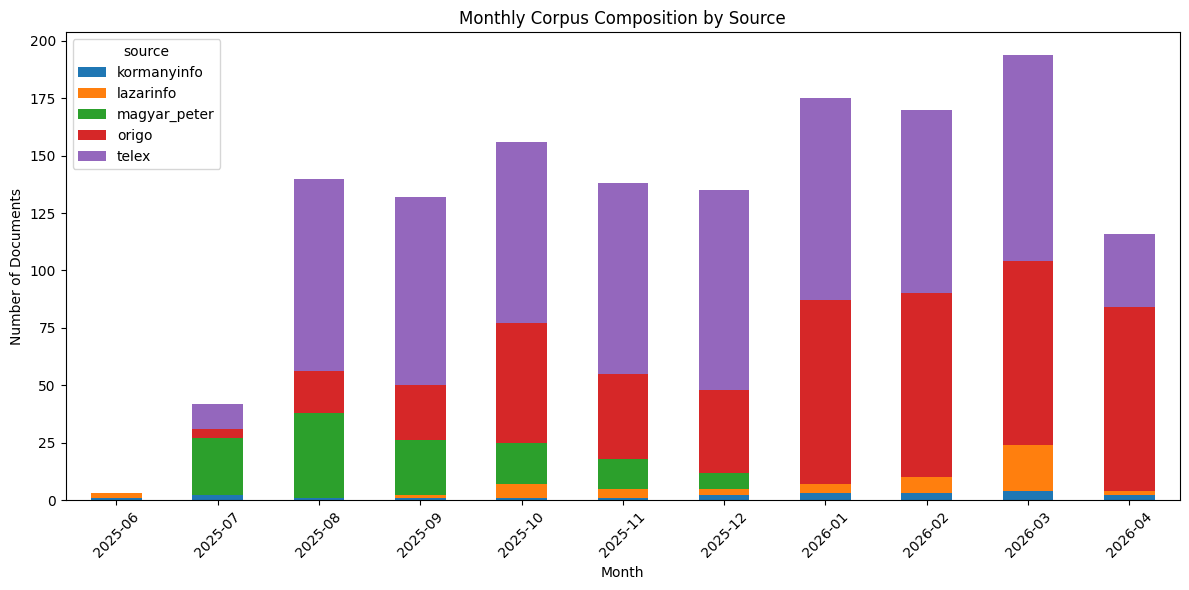

In [43]:
monthly_source = (
    df.groupby(["month", "source"])
    .size()
    .reset_index(name="documents")
)

monthly_pivot = monthly_source.pivot(
    index="month",
    columns="source",
    values="documents"
).fillna(0)

monthly_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Monthly Corpus Composition by Source")
plt.xlabel("Month")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Sentiment Scoring

In [44]:
#Model configuration: HuggingFace model IDs used by the sentiment, ABSA, andtopic-modelling pipelines

CFG = {
    # Multilingual XLM-R-base, 3-class sentiment classifier
    "sentiment_model_a": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    # Hungarian-specific XLM-R-base, 5-class HTS5 sentiment classifier
    "sentiment_model_b": "NYTK/sentiment-hts5-xlm-roberta-hungarian",
    # Multilingual sentence embedder used by BERTopic
    "embed_model": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    # huSpaCy model used for Hungarian sentence segmentation in the ABSA pipeline
    "huspacy_model": "hu_core_news_md",
    "device": "cpu",
    "batch_size": 8,
    "max_length": 512,
}

In [45]:
#Document-level polarity ensemble
from __future__ import annotations


import time
from dataclasses import dataclass
from typing import Iterable

import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

LABELS_3 = ["negative", "neutral", "positive"]
LABEL_VAL = np.array([-1.0, 0.0, 1.0])


@dataclass
class Predictor:
    name: str
    tokenizer: object
    model: object
    label_map: list[str]

    @staticmethod
    def load(model_id: str, device: str = "cpu") -> "Predictor":
        tok = AutoTokenizer.from_pretrained(model_id, use_fast=False)
        mdl = AutoModelForSequenceClassification.from_pretrained(model_id)
        mdl.eval()
        if device == "cuda" and torch.cuda.is_available():
            mdl = mdl.to("cuda")
        labels = [
            mdl.config.id2label[i].lower() for i in range(mdl.config.num_labels)
        ]
        return Predictor(name=model_id, tokenizer=tok, model=mdl, label_map=labels)

    def to_3class(self, probs: np.ndarray) -> np.ndarray:
        """Project the model's native label set onto [neg, neu, pos].

        Handles three label schemes:
          - 3-class semantic: {negative, neutral, positive} (Cardiff)
          - 5-class HTS5: LABEL_0..LABEL_4 with 0,1=neg, 2=neu, 3,4=pos (NYTK)
          - Generic LABEL_N for arbitrary N
        """
        out = np.zeros(3, dtype=float)
        n = len(self.label_map)
        for i, lbl in enumerate(self.label_map):
            l = lbl.lower()
            if "neg" in l or l == "strongly_negative":
                out[0] += probs[i]
            elif "neu" in l:
                out[1] += probs[i]
            elif "pos" in l or l == "strongly_positive":
                out[2] += probs[i]
            elif l.startswith("label_"):
                idx = int(l.split("_", 1)[1])
                if n == 5:
                    if idx <= 1:
                        out[0] += probs[i]
                    elif idx == 2:
                        out[1] += probs[i]
                    else:
                        out[2] += probs[i]
                elif n == 3:
                    out[idx] += probs[i]
                else:
                    out[1] += probs[i]
            else:
                out[1] += probs[i]
        s = out.sum()
        return out / s if s > 0 else np.array([1 / 3, 1 / 3, 1 / 3])


def _chunk_text(text: str, tok, max_length: int = 512, max_chunks: int = 5) -> list[str]:
    """Sample up to `max_chunks` evenly-spaced word windows from the doc.

    For very long docs (Lázárinfó avg 17,878 words) running every chunk is
    intractable on CPU. Five evenly-spaced ~360-word windows capture the doc's
    overall sentiment well enough for daily-aggregate downstream use.
    """
    if not isinstance(text, str) or not text:
        return [""]
    words = text.split()
    n = len(words)
    if not n:
        return [""]
    chunk_words = max(40, int(max_length * 0.7))
    if n <= chunk_words:
        return [text]
    if n <= chunk_words * max_chunks:
        return [
            " ".join(words[i:i + chunk_words])
            for i in range(0, n, chunk_words)
        ]
    starts = np.linspace(0, n - chunk_words, max_chunks, dtype=int)
    return [" ".join(words[s:s + chunk_words]) for s in starts]


@torch.no_grad()
def _predict_batch(predictor: Predictor, texts: list[str], device: str,
                   max_length: int = 512) -> np.ndarray:
    enc = predictor.tokenizer(
        texts, padding=True, truncation=True, max_length=max_length,
        return_tensors="pt",
    )
    if device == "cuda" and torch.cuda.is_available():
        enc = {k: v.to("cuda") for k, v in enc.items()}
    logits = predictor.model(**enc).logits.detach().cpu().numpy()
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def predict_docs(
    docs: pd.DataFrame,
    text_col: str = "text_clean",
    id_col: str = "doc_id",
    batch_size: int = 8,
    max_length: int = 512,
    progress_every: int = 50,
) -> pd.DataFrame:
    """Run the configured ensemble over a DataFrame of documents.

    Returns one row per doc:
        doc_id, p_neg_a, p_neu_a, p_pos_a, score_a,
                p_neg_b, p_neu_b, p_pos_b, score_b,
                p_neg, p_neu, p_pos, score_ensemble
    """
    device = CFG["device"]
    pa = Predictor.load(CFG["sentiment_model_a"], device=device)
    pb = Predictor.load(CFG["sentiment_model_b"], device=device)

    rows = []
    n = len(docs)
    t0 = time.time()
    for i, (idx, doc) in enumerate(docs.iterrows()):
        text = doc.get(text_col) or ""
        chunks = _chunk_text(text, pa.tokenizer, max_length=max_length)
        # Predictor A
        chunk_probs_a = []
        for j in range(0, len(chunks), batch_size):
            p = _predict_batch(pa, chunks[j:j + batch_size], device, max_length)
            chunk_probs_a.append(p)
        a_probs = np.concatenate(chunk_probs_a, axis=0).mean(axis=0)
        a_3 = pa.to_3class(a_probs)
        # Predictor B
        chunk_probs_b = []
        for j in range(0, len(chunks), batch_size):
            p = _predict_batch(pb, chunks[j:j + batch_size], device, max_length)
            chunk_probs_b.append(p)
        b_probs = np.concatenate(chunk_probs_b, axis=0).mean(axis=0)
        b_3 = pb.to_3class(b_probs)
        ens_3 = (a_3 + b_3) / 2.0
        rows.append({
            id_col: doc[id_col],
            "p_neg_a": a_3[0], "p_neu_a": a_3[1], "p_pos_a": a_3[2],
            "score_a": float(a_3 @ LABEL_VAL),
            "p_neg_b": b_3[0], "p_neu_b": b_3[1], "p_pos_b": b_3[2],
            "score_b": float(b_3 @ LABEL_VAL),
            "p_neg": ens_3[0], "p_neu": ens_3[1], "p_pos": ens_3[2],
            "score_ensemble": float(ens_3 @ LABEL_VAL),
            "n_chunks": len(chunks),
        })
        if (i + 1) % progress_every == 0 or (i + 1) == n:
            elapsed = time.time() - t0
            rate = (i + 1) / max(elapsed, 1e-6)
            eta = (n - (i + 1)) / max(rate, 1e-6)
            print(f"  [{i + 1}/{n}] elapsed={elapsed:.0f}s rate={rate:.2f}/s "
                  f"eta={eta:.0f}s ({eta / 60:.1f}min)")
    return pd.DataFrame(rows)


def predict_sentences(
    sentences: list[str],
    predictor_id: str = "a",
    batch_size: int = 16,
    max_length: int = 256,
) -> np.ndarray:
    """Lower-level helper for ABSA — returns 3-class probs for a list of sentences."""
    device = CFG["device"]
    model_id = CFG["sentiment_model_a"] if predictor_id == "a" else CFG["sentiment_model_b"]
    pred = Predictor.load(model_id, device=device)
    out = []
    for i in range(0, len(sentences), batch_size):
        batch = sentences[i:i + batch_size]
        if not batch:
            continue
        probs = _predict_batch(pred, batch, device, max_length)
        proj = np.array([pred.to_3class(p) for p in probs])
        out.append(proj)
    return np.concatenate(out, axis=0) if out else np.zeros((0, 3))

In [46]:
#run sentiment ensemble on the full usable corpus.
import csv
import os
import sys
import time

import pandas as pd


def main():
    corpus = pd.read_csv("corpus_master.csv")
    use = corpus[corpus["is_usable"]].copy()
    print(f"usable docs: {len(use)}", flush=True)

    out_path = "sentiment_doc.csv"
    if os.path.exists(out_path):
        prior = pd.read_csv(out_path)
        done = set(prior["doc_id"].astype(str).tolist())
        use = use[~use["doc_id"].astype(str).isin(done)]
        print(f"already-scored: {len(done)}, remaining: {len(use)}", flush=True)
    else:
        prior = pd.DataFrame()

    if use.empty:
        print("nothing to do")
        return

    use_text = use[["doc_id", "text_clean"]].copy()
    use_text["text_clean"] = use_text["text_clean"].fillna("").astype(str)

    t0 = time.time()
    new = predict_docs(use_text, batch_size=CFG["batch_size"],
                       max_length=CFG["max_length"], progress_every=25)
    elapsed = time.time() - t0
    print(f"\nB1 done: {len(new)} new docs in {elapsed:.0f}s "
          f"({elapsed / max(len(new), 1):.2f}s/doc)", flush=True)

    out = pd.concat([prior, new], ignore_index=True) if len(prior) else new
    out.to_csv(out_path, index=False, quoting=csv.QUOTE_MINIMAL,
               lineterminator="\n", encoding="utf-8")
    print(f"wrote {out_path} ({len(out)} rows)", flush=True)


if __name__ == "__main__":
    main()
    #This runs for a long time, we will attach the output ("sentiment_doc.csv")

usable docs: 1345
already-scored: 1585, remaining: 0
nothing to do


In [22]:
!pip install huspacy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.8/92.8 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 2.9 MB/s eta 0:00:00
  Attempting uninstall: packaging
    Found existing installation: packaging 26.1
    Uninstalling packaging-26.1:
      Successfully uninstalled packaging-26.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 21.3 which is incompatible.
pysal 25.7 requires packaging>=22, but you have packaging 21.3 which is incompatible.
db-dtypes 1.5.1 requires packaging>=24.2.0, but you have packaging 21.3 which is incompatible.
wheel 0.47.0 requires packaging>=24.0, but you have packaging 21.3 which is incompatible.
libpysal 4.14.1 requires packaging>=23.2, but you have packaging 21.3 which is incompatible.
google-cloud-bigquery 3.41.0 requires packaging

In [4]:
!python -c "import huspacy; huspacy.download('hu_core_news_md')"

['/usr/bin/python3', '-m', 'pip', 'install', 'hu_core_news_md @ https://huggingface.co/huspacy/hu_core_news_md/resolve/v3.8.0/hu_core_news_md-any-py3-none-any.whl']
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.0/127.0 MB 9.7 MB/s eta 0:00:00


In [5]:
#Aspect-Based Sentiment Analysis.
from __future__ import annotations

import re
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd

ASPECTS = ["fidesz_orban", "tisza_mp"]

ASPECT_PATTERNS = {
    "fidesz_orban": re.compile(
        r"\bfidesz\w*|\borb[áa]n\w*|\bkdnp\w*",
        re.IGNORECASE | re.UNICODE,
    ),
    "tisza_mp": re.compile(
        r"\btisza\w*|\bmagyar\s+p[ée]ter\w*|\bp[ée]ter\s+magyar\w*",
        re.IGNORECASE | re.UNICODE,
    ),
}


def detect_aspects(sentence: str) -> dict[str, bool]:
    s = sentence or ""
    return {a: bool(p.search(s)) for a, p in ASPECT_PATTERNS.items()}


@dataclass
class SegResult:
    doc_id: str
    sentences: list[str]
    aspect_indices: dict[str, list[int]]


def segment_doc(doc_id: str, text: str, nlp) -> SegResult:
    if not isinstance(text, str) or not text.strip():
        return SegResult(doc_id=doc_id, sentences=[], aspect_indices={a: [] for a in ASPECTS})
    text = text[:200_000]
    doc = nlp(text)
    sentences = [s.text.strip() for s in doc.sents if s.text.strip()]
    idx = {a: [] for a in ASPECTS}
    for i, s in enumerate(sentences):
        for a, hit in detect_aspects(s).items():
            if hit:
                idx[a].append(i)
    return SegResult(doc_id=doc_id, sentences=sentences, aspect_indices=idx)


def score_aspects_for_doc(seg: SegResult, score_fn) -> dict:
    """Returns dict with score_<aspect> and n_sent_<aspect> per aspect."""
    row = {"doc_id": seg.doc_id, "n_sentences": len(seg.sentences)}
    for a in ASPECTS:
        idxs = seg.aspect_indices[a]
        n = len(idxs)
        row[f"n_sent_{a}"] = n
        if n == 0:
            row[f"score_{a}"] = np.nan
            continue
        sents = [seg.sentences[i] for i in idxs]
        try:
            scores = score_fn(sents)
        except Exception:
            row[f"score_{a}"] = np.nan
            continue
        row[f"score_{a}"] = float(np.nanmean(scores)) if len(scores) else np.nan
    return row


def make_score_fn():

    def _score(sentences: list[str]) -> np.ndarray:
        if not sentences:
            return np.zeros(0)
        probs_a = predict_sentences(sentences, predictor_id="a", batch_size=16,
                                    max_length=256)
        probs_b = predict_sentences(sentences, predictor_id="b", batch_size=16,
                                    max_length=256)
        ens = (probs_a + probs_b) / 2.0
        return ens @ LABEL_VAL

    return _score


def load_huspacy():
    import spacy
    return spacy.load("hu_core_news_md")


In [6]:
#run ABSA on the full usable corpus.
import csv
import os
import sys
import time
import numpy as np
import pandas as pd


def main():
    corpus = pd.read_csv("corpus_master.csv")
    use = corpus[corpus["is_usable"]].copy()
    use["text_clean"] = use["text_clean"].fillna("").astype(str)
    print(f"usable docs: {len(use)}", flush=True)

    out_path = "absa_doc.csv"
    if os.path.exists(out_path):
        prior = pd.read_csv(out_path)
        done = set(prior["doc_id"].astype(str))
        use = use[~use["doc_id"].astype(str).isin(done)]
        print(f"already-scored: {len(done)}, remaining: {len(use)}", flush=True)
    else:
        prior = pd.DataFrame()

    if use.empty:
        print("nothing to do")
        return

    print("loading huSpaCy...", flush=True)
    nlp = load_huspacy()
    print("loading sentiment models...", flush=True)
    score_fn = make_score_fn()

    rows = []
    t0 = time.time()
    for i, (idx, doc) in enumerate(use.iterrows()):
        seg = segment_doc(doc["doc_id"], doc["text_clean"], nlp)
        row = score_aspects_for_doc(seg, score_fn)
        rows.append(row)
        if (i + 1) % 10 == 0 or (i + 1) == len(use):
            elapsed = time.time() - t0
            rate = (i + 1) / max(elapsed, 1e-6)
            eta = (len(use) - (i + 1)) / max(rate, 1e-6)
            print(f"  [{i + 1}/{len(use)}] {elapsed:.0f}s  rate={rate:.2f}/s "
                  f"eta={eta:.0f}s ({eta / 60:.1f}min)", flush=True)

    new = pd.DataFrame(rows)
    out = pd.concat([prior, new], ignore_index=True) if len(prior) else new
    out.to_csv(out_path, index=False, quoting=csv.QUOTE_MINIMAL,
               lineterminator="\n", encoding="utf-8")
    print(f"\nwrote {out_path} ({len(out)} rows)", flush=True)
    summary = (
        out[[f"score_{a}" for a in ASPECTS]]
        .describe(percentiles=[0.5])
        .round(3)
        .to_string()
    )
    print(summary, flush=True)


if __name__ == "__main__":
    main()
    #runs for a long time, the output absa_doc.csv is attached

usable docs: 1345
loading huSpaCy...
loading sentiment models...
  [10/1345] 10s  rate=0.96/s eta=1393s (23.2min)
  [20/1345] 19s  rate=1.08/s eta=1229s (20.5min)
  [30/1345] 26s  rate=1.17/s eta=1126s (18.8min)
  [40/1345] 39s  rate=1.02/s eta=1278s (21.3min)
  [50/1345] 57s  rate=0.88/s eta=1465s (24.4min)


KeyboardInterrupt: 

In [7]:
#builds daily sentiment indices from per-doc sentiment scores.
import csv
import os
import pandas as pd
import numpy as np

ASPECTS_DEFAULT = ["overall"]
SOURCES = ["kormanyinfo", "lazarinfo", "magyar_peter", "telex", "origo"]


def _weighted_daily(df: pd.DataFrame, score_col: str,
                    weight_col: str = "n_words_clean") -> pd.DataFrame:
    """Weighted-mean per (date, source). Returns wide-form daily index."""
    df = df.copy()
    df["w"] = df[weight_col].clip(lower=1)
    df["wv"] = df["w"] * df[score_col]
    g = df.groupby(["date", "source"]).agg(
        sum_wv=("wv", "sum"),
        sum_w=("w", "sum"),
        n_docs=("doc_id", "nunique"),
    ).reset_index()
    g["score"] = g["sum_wv"] / g["sum_w"]
    return g[["date", "source", "score", "n_docs", "sum_w"]].rename(
        columns={"sum_w": "n_words"}
    )


def build():
    corpus = pd.read_csv("corpus_master.csv")
    sent = pd.read_csv("sentiment_doc.csv")
    df = corpus.merge(sent, on="doc_id", how="left")
    df = df[df["is_usable"]].copy()
    df = df.dropna(subset=["score_ensemble"])

    daily_overall = _weighted_daily(df, "score_ensemble")
    daily_overall["aspect"] = "overall"

    parts = [daily_overall]

    absa_path ="absa_doc.csv"
    # Changed absa_path.exists() to os.path.exists(absa_path)
    if os.path.exists(absa_path):
        absa = pd.read_csv(absa_path)
        absa_long = absa.melt(
            id_vars=["doc_id"],
            value_vars=[c for c in absa.columns if c.startswith("score_")
                        and c != "score_ensemble"],
            var_name="aspect_col",
            value_name="score",
        )
        absa_long["aspect"] = absa_long["aspect_col"].str.replace("score_", "", n=1)
        absa_long = absa_long.drop(columns=["aspect_col"])
        absa_long = absa_long.dropna(subset=["score"])
        meta = corpus[["doc_id", "date", "source", "n_words_clean", "is_usable"]]
        joined = absa_long.merge(meta, on="doc_id")
        joined = joined[joined["is_usable"]]
        for asp, sub in joined.groupby("aspect"):
            d = _weighted_daily(sub.assign(score_=sub["score"]), "score_")
            d["aspect"] = asp
            parts.append(d)

    long_df = pd.concat(parts, ignore_index=True)

    full_idx = pd.date_range("2025-07-28", "2026-04-17", freq="D")
    pieces = []
    for (source, aspect), sub in long_df.groupby(["source", "aspect"]):
        sub = sub.copy()
        sub["date"] = pd.to_datetime(sub["date"])
        sub = sub.set_index("date").sort_index()
        s_score = sub["score"].reindex(full_idx)
        s_n_docs = sub["n_docs"].reindex(full_idx).fillna(0).astype(int)
        s_n_words = sub["n_words"].reindex(full_idx).fillna(0).astype(int)
        s_score = s_score.fillna(s_score.rolling(3, min_periods=1, center=True).mean())
        s_score = s_score.ffill().bfill()
        pieces.append(pd.DataFrame({
            "date": full_idx.strftime("%Y-%m-%d"),
            "source": source, "aspect": aspect,
            "score": s_score.values,
            "n_docs": s_n_docs.values,
            "n_words": s_n_words.values,
        }))
    out = pd.concat(pieces, ignore_index=True)

    out_path = "sentiment_daily.csv"
    out.to_csv(out_path, index=False, quoting=csv.QUOTE_MINIMAL,
               lineterminator="\n", encoding="utf-8")
    return out_path, out


if __name__ == "__main__":
    out_path, out = build()
    print(f"wrote {out_path} ({out.shape})")
    print("by (source, aspect):")
    print(out.groupby(["source", "aspect"]).size().to_string())
    print(f"date range: {out['date'].min()} -> {out['date'].max()}")

wrote sentiment_daily.csv ((3960, 6))
by (source, aspect):
source        aspect      
kormanyinfo   fidesz_orban    264
              overall         264
              tisza_mp        264
lazarinfo     fidesz_orban    264
              overall         264
              tisza_mp        264
magyar_peter  fidesz_orban    264
              overall         264
              tisza_mp        264
origo         fidesz_orban    264
              overall         264
              tisza_mp        264
telex         fidesz_orban    264
              overall         264
              tisza_mp        264
date range: 2025-07-28 -> 2026-04-17


In [8]:
"""hand-curated populism / threat framing dictionary.

Hungarian populist + threat-framing lexicon (~60 entries). Two daily indices:
  - populism_score = mean per-doc populism term frequency / 1000 words
  - threat_score   = mean per-doc threat term frequency / 1000 words

Categories follow the comparative-politics literature on populist discourse
(Mudde 2004, Hawkins 2009, Aslanidis 2018) adapted to the 2026 Hungarian
election context.
"""
from __future__ import annotations

import re
import unicodedata
from typing import Iterable

import numpy as np
import pandas as pd

# People-vs-elite framing (us-vs-them, sovereignty, nationalism)
# Stems chosen so \w* in _compile_terms catches morphological variants
# (e.g. "lop" matches lopnak, ellopnak, elloptak, loptak, lopott).
POPULISM_TERMS = [
    "nép", "magyar emberek", "nemzet", "haza", "hazaárul",
    "elit", "globális elit", "liberális elit", "brüsszeli elit",
    "globalist", "soros",
    "elit szembe", "elit ellen", "rendszerváltás",
    "magyar érdek", "nemzeti szuverenitás", "nemzeti sors",
    "korrupt elit", "korrupt politikus", "korrupciós", "lop",
    "bürokrata", "bürokrácia",
    "eszközölik", "kihasznál", "becsap", "mosakszik",
    "valódi", "igazi magyar", "őszinte",
    "döntsenek a magyarok", "magyar emberek döntik el",
]

# Threat / fear / security framing
THREAT_TERMS = [
    "veszély", "veszélyez", "fenyege", "támadás", "támadnak",
    "háború", "háborús", "nato",
    "migráns", "migráció", "migránssimog", "illegális",
    "terror", "terrorista",
    "lebomb", "tönkretesz", "elvesz", "elveszít",
    "katasztrof", "összeoml", "csőd",
    "válság", "krízis",
    "bevándor", "bevándorolt",
    "drog", "kábítószer",
    "lgbt", "gender", "genderőrület", "genderpropaganda",
    "ellenség", "ellenségkép",
    "elragadnak", "kifoszt",
    "bűnöz", "bűncselekmény",
    "diktatúra", "rendőrállam", "szovjet",
]


def _normalize(s: str) -> str:
    if not isinstance(s, str):
        return ""
    s = unicodedata.normalize("NFKC", s).lower()
    return re.sub(r"\s+", " ", s)


def _compile_terms(terms: list[str]) -> re.Pattern:
    parts = [re.escape(_normalize(t)) for t in terms]
    return re.compile("|".join(rf"\b{p}\w*" for p in parts), re.IGNORECASE | re.UNICODE)


POPULISM_RE = _compile_terms(POPULISM_TERMS)
THREAT_RE = _compile_terms(THREAT_TERMS)


def doc_scores(text: str, n_words: int | None = None) -> dict[str, float]:
    norm = _normalize(text)
    if n_words is None:
        n_words = max(1, len(norm.split()))
    pop = len(POPULISM_RE.findall(norm))
    thr = len(THREAT_RE.findall(norm))
    return {
        "populism_count": pop,
        "threat_count": thr,
        "populism_per_1k": 1000.0 * pop / max(n_words, 1),
        "threat_per_1k": 1000.0 * thr / max(n_words, 1),
    }


def score_corpus(corpus: pd.DataFrame, text_col: str = "text_clean",
                 n_col: str = "n_words_clean") -> pd.DataFrame:
    rows = []
    for _, r in corpus.iterrows():
        s = doc_scores(r[text_col] or "", r[n_col] or 1)
        s["doc_id"] = r["doc_id"]
        rows.append(s)
    return pd.DataFrame(rows)


if __name__ == "__main__":
    test = (
        "A migránsválság veszélyezteti a magyar embereket. "
        "Brüsszel és a globalista elit szembe áll a nemzeti szuverenitással. "
        "A bevándorlás háborúhoz vezet és terrorveszélyt jelent."
    )
    print(doc_scores(test))

{'populism_count': 4, 'threat_count': 5, 'populism_per_1k': 173.91304347826087, 'threat_per_1k': 217.3913043478261}


In [9]:
#build daily populism + threat framing indices per source.
import csv
import numpy as np
import pandas as pd

def build():
    corpus = pd.read_csv("corpus_master.csv")
    use = corpus[corpus["is_usable"]].copy()

    print(f"scoring framing on {len(use)} usable docs ...", flush=True)
    # Assuming score_corpus is defined elsewhere in your Colab environment
    doc = score_corpus(use, text_col="text_clean", n_col="n_words_clean")
    doc.to_csv("framing_doc.csv", index=False,
               quoting=csv.QUOTE_MINIMAL, lineterminator="\n", encoding="utf-8")

    merged = use.merge(doc, on="doc_id")
    merged["w"] = merged["n_words_clean"].clip(lower=1)

    rows = []
    full_idx = pd.date_range("2025-07-28", "2026-04-17", freq="D")
    for src, sub in merged.groupby("source"):
        sub["date"] = pd.to_datetime(sub["date"])
        agg = (sub.groupby("date").apply(
            lambda g: pd.Series({
                "populism_score": np.average(g["populism_per_1k"], weights=g["w"]),
                "threat_score": np.average(g["threat_per_1k"], weights=g["w"]),
                "n_docs": int(len(g)),
            })
        ).reindex(full_idx).rename_axis("date").reset_index())
        agg["populism_score"] = agg["populism_score"].fillna(
            agg["populism_score"].rolling(3, min_periods=1, center=True).mean()
        ).ffill().bfill()
        agg["threat_score"] = agg["threat_score"].fillna(
            agg["threat_score"].rolling(3, min_periods=1, center=True).mean()
        ).ffill().bfill()
        agg["n_docs"] = agg["n_docs"].fillna(0).astype(int)
        agg["source"] = src
        rows.append(agg)

    daily = pd.concat(rows, ignore_index=True)
    daily["date"] = pd.to_datetime(daily["date"]).dt.strftime("%Y-%m-%d")
    daily = daily[["date", "source", "populism_score", "threat_score", "n_docs"]]
    daily.to_csv("framing_daily.csv", index=False,
                 quoting=csv.QUOTE_MINIMAL, lineterminator="\n", encoding="utf-8")
    print(f"wrote framing_daily.csv ({daily.shape})", flush=True)
    print(daily.groupby("source")[["populism_score", "threat_score"]].mean().round(2).to_string())


if __name__ == "__main__":
    build()

scoring framing on 1345 usable docs ...


/tmp/ipykernel_25167/2147132534.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  agg = (sub.groupby("date").apply(
/tmp/ipykernel_25167/2147132534.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  agg = (sub.groupby("date").apply(
/tmp/ipykernel_25167/2147132534.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of 

wrote framing_daily.csv ((1320, 5))
              populism_score  threat_score
source                                    
kormanyinfo             3.00          4.50
lazarinfo               1.62          3.61
magyar_peter            7.74          2.85
origo                   4.91          6.75
telex                   3.45          3.58


/tmp/ipykernel_25167/2147132534.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  agg = (sub.groupby("date").apply(


# Sentiment Score Validation

In [10]:
sent_doc = pd.read_csv("sentiment_doc.csv")
sent_daily = pd.read_csv("sentiment_daily.csv")
absa_doc = pd.read_csv("absa_doc.csv")
framing_doc = pd.read_csv("framing_doc.csv")
framing_daily = pd.read_csv("framing_daily.csv")

sent_daily["date"] = pd.to_datetime(sent_daily["date"])
framing_daily["date"] = pd.to_datetime(framing_daily["date"])

In [11]:
print("sentiment_doc shape:", sent_doc.shape)
print("sentiment_daily shape:", sent_daily.shape)
print("absa_doc shape:", absa_doc.shape)
print("framing_doc shape:", framing_doc.shape)
print("framing_daily shape:", framing_daily.shape)

print("\nMissing values in sentiment_doc:")
print(sent_doc.isna().sum())

print("\nMissing values in sentiment_daily:")
print(sent_daily.isna().sum())

sentiment_doc shape: (1585, 14)
sentiment_daily shape: (3960, 6)
absa_doc shape: (1585, 6)
framing_doc shape: (1345, 5)
framing_daily shape: (1320, 5)

Missing values in sentiment_doc:
doc_id            0
p_neg_a           0
p_neu_a           0
p_pos_a           0
score_a           0
p_neg_b           0
p_neu_b           0
p_pos_b           0
score_b           0
p_neg             0
p_neu             0
p_pos             0
score_ensemble    0
n_chunks          0
dtype: int64

Missing values in sentiment_daily:
date       0
source     0
aspect     0
score      0
n_docs     0
n_words    0
dtype: int64


In [12]:
print("Duplicate doc_ids in sentiment_doc:")
print(sent_doc["doc_id"].duplicated().sum())

print("\nDuplicate date-source-aspect rows in sentiment_daily:")
print(sent_daily.duplicated(["date", "source", "aspect"]).sum())

Duplicate doc_ids in sentiment_doc:
0

Duplicate date-source-aspect rows in sentiment_daily:
0


In [13]:
prob_cols = ["p_neg", "p_neu", "p_pos"]

sent_doc["prob_sum"] = sent_doc[prob_cols].sum(axis=1)

print("Probability sum summary:")
print(sent_doc["prob_sum"].describe())

print("\nRows where probabilities do not sum to approximately 1:")
print(sent_doc[~np.isclose(sent_doc["prob_sum"], 1, atol=0.01)])

Probability sum summary:
count    1.585000e+03
mean     1.000000e+00
std      1.158919e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: prob_sum, dtype: float64

Rows where probabilities do not sum to approximately 1:
Empty DataFrame
Columns: [doc_id, p_neg_a, p_neu_a, p_pos_a, score_a, p_neg_b, p_neu_b, p_pos_b, score_b, p_neg, p_neu, p_pos, score_ensemble, n_chunks, prob_sum]
Index: []


In [14]:
score_cols_doc = ["score_a", "score_b", "score_ensemble"]

for col in score_cols_doc:
    print(f"\n{col} range:")
    print(sent_doc[col].min(), sent_doc[col].max())

    invalid = sent_doc[~sent_doc[col].between(-1, 1)]
    print(f"Invalid {col} values:", len(invalid))

print("\nDaily sentiment score range:")
print(sent_daily["score"].min(), sent_daily["score"].max())

print("\nInvalid daily scores:")
print(sent_daily[~sent_daily["score"].between(-1, 1)])


score_a range:
-0.4919841142897572 0.7506096940533049
Invalid score_a values: 0

score_b range:
-0.8337660691712729 0.8794347283873373
Invalid score_b values: 0

score_ensemble range:
-0.5669410032365753 0.78552662561486
Invalid score_ensemble values: 0

Daily sentiment score range:
-0.8212237356850155 0.78552662561486

Invalid daily scores:
Empty DataFrame
Columns: [date, source, aspect, score, n_docs, n_words]
Index: []


In [15]:
sent_doc["model_difference"] = abs(sent_doc["score_a"] - sent_doc["score_b"])

print("Model disagreement summary:")
print(sent_doc["model_difference"].describe())

print("\nLargest model disagreements:")
print(sent_doc.sort_values("model_difference", ascending=False).head(10)[
    ["doc_id", "score_a", "score_b", "score_ensemble", "model_difference"]
])

Model disagreement summary:
count    1585.000000
mean        0.275945
std         0.199101
min         0.000060
25%         0.106924
50%         0.238793
75%         0.426511
max         0.920852
Name: model_difference, dtype: float64

Largest model disagreements:
                                                 doc_id   score_a   score_b  \
865              onos-eso-kialakulas-veszely-tudnivalok  0.247630 -0.673223   
1568                        magyarpeter_20260121_kR07Y8  0.196423 -0.695571   
888                    kapu-tibor-dij-media-bal-urhajos -0.015859  0.834151   
976               gesztesi-panka-a-nagy-duett-elso-show  0.010017  0.848058   
742                                bajban-lesz-a-fidesz  0.078682 -0.754024   
988      tisza-part-magyar-peter-csokken-figyelem-hakni  0.042601 -0.779726   
286   budapest-fovaros-koltsegvetes-csodhelyzet-szak...  0.013842 -0.808421   
346                          lerobbant-a-mav-fenyvonata  0.046242 -0.773279   
767        orban-viktor-

In [16]:
print("Daily document count summary:")
print(sent_daily["n_docs"].describe())

print("\nRows with n_docs = 0:")
print(sent_daily[sent_daily["n_docs"] == 0].head())

print("\nRows where n_docs = 0 but score is not missing:")
print(sent_daily[(sent_daily["n_docs"] == 0) & (sent_daily["score"].notna())].head())

print("\nRows with negative n_docs or n_words:")
print(sent_daily[(sent_daily["n_docs"] < 0) | (sent_daily["n_words"] < 0)])

Daily document count summary:
count    3960.000000
mean        0.759091
std         1.174170
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max        11.000000
Name: n_docs, dtype: float64

Rows with n_docs = 0:
        date       source        aspect     score  n_docs  n_words
0 2025-07-28  kormanyinfo  fidesz_orban -0.348886       0        0
1 2025-07-29  kormanyinfo  fidesz_orban -0.348886       0        0
2 2025-07-30  kormanyinfo  fidesz_orban -0.348886       0        0
4 2025-08-01  kormanyinfo  fidesz_orban -0.348886       0        0
5 2025-08-02  kormanyinfo  fidesz_orban -0.348886       0        0

Rows where n_docs = 0 but score is not missing:
        date       source        aspect     score  n_docs  n_words
0 2025-07-28  kormanyinfo  fidesz_orban -0.348886       0        0
1 2025-07-29  kormanyinfo  fidesz_orban -0.348886       0        0
2 2025-07-30  kormanyinfo  fidesz_orban -0.348886       0        0
4 2025-08-01  kormanyinfo  fide

In [17]:
absa_score_cols = ["score_fidesz_orban", "score_tisza_mp"]

for col in absa_score_cols:
    print(f"\n{col} range:")
    print(absa_doc[col].min(), absa_doc[col].max())

    invalid = absa_doc[~absa_doc[col].between(-1, 1)]
    print(f"Invalid {col} values:", len(invalid))


score_fidesz_orban range:
-0.8819131282517525 0.7375692746853832
Invalid score_fidesz_orban values: 369

score_tisza_mp range:
-0.8625485351746195 0.6766006443306574
Invalid score_tisza_mp values: 608


In [18]:
print("Framing daily missing values:")
print(framing_daily.isna().sum())

print("\nNegative framing scores:")
print(framing_daily[
    (framing_daily["populism_score"] < 0) |
    (framing_daily["threat_score"] < 0)
])

Framing daily missing values:
date              0
source            0
populism_score    0
threat_score      0
n_docs            0
dtype: int64

Negative framing scores:
Empty DataFrame
Columns: [date, source, populism_score, threat_score, n_docs]
Index: []


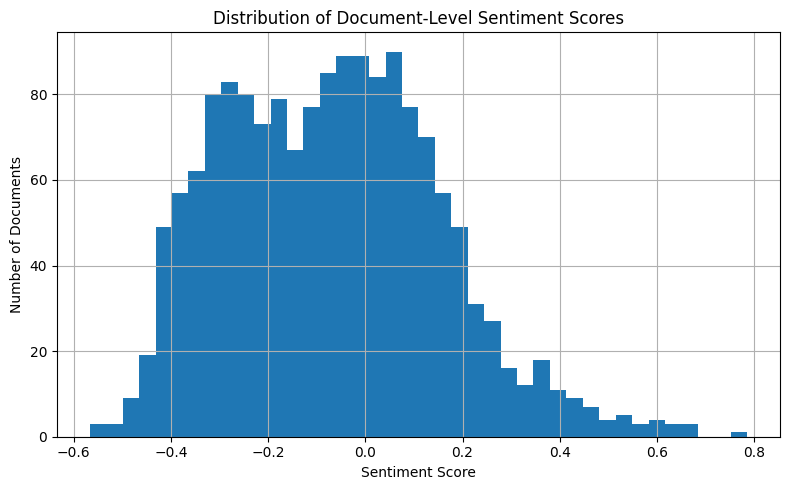

In [20]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
sent_doc["score_ensemble"].hist(bins=40)
plt.title("Distribution of Document-Level Sentiment Scores")
plt.xlabel("Sentiment Score")
plt.ylabel("Number of Documents")
plt.tight_layout()
plt.show()

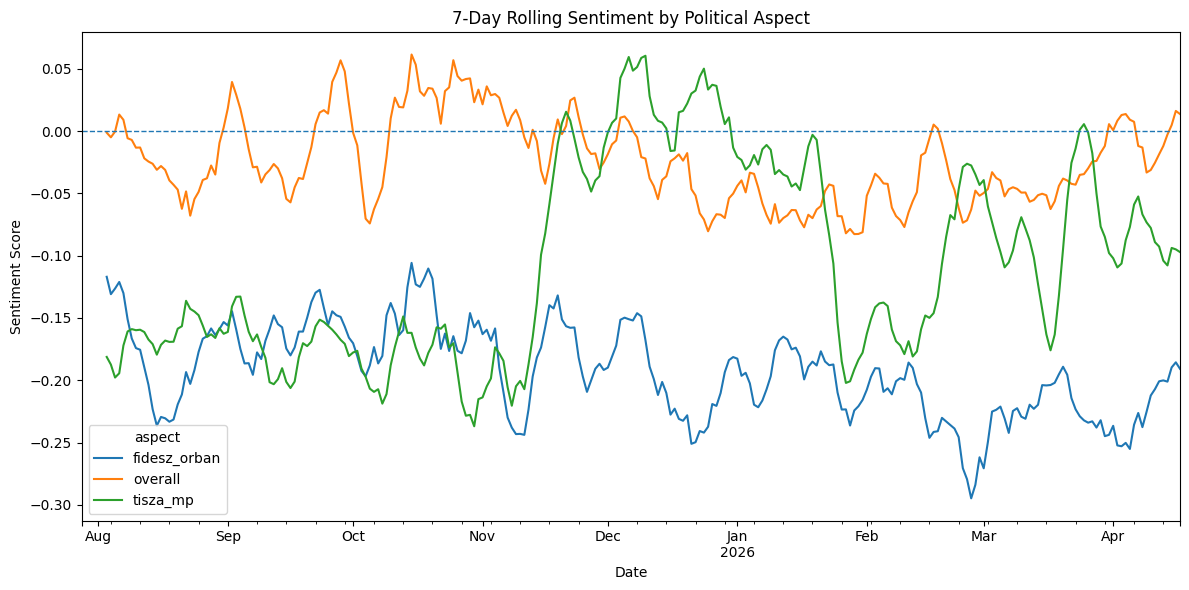

In [21]:
daily_aspect = sent_daily.pivot_table(
    index="date",
    columns="aspect",
    values="score",
    aggfunc="mean"
)

daily_aspect.rolling(7).mean().plot(figsize=(12, 6))

plt.axhline(0, linestyle="--", linewidth=1)
plt.title("7-Day Rolling Sentiment by Political Aspect")
plt.xlabel("Date")
plt.ylabel("Sentiment Score")
plt.tight_layout()
plt.show()

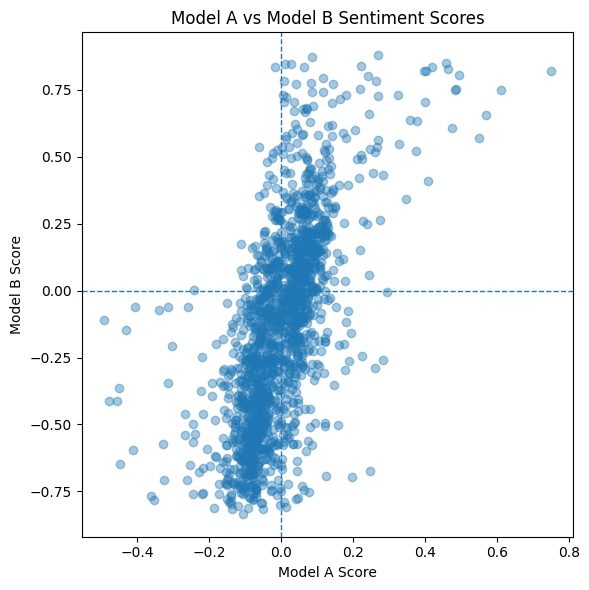

In [22]:
plt.figure(figsize=(6, 6))
plt.scatter(sent_doc["score_a"], sent_doc["score_b"], alpha=0.4)
plt.axhline(0, linestyle="--", linewidth=1)
plt.axvline(0, linestyle="--", linewidth=1)
plt.title("Model A vs Model B Sentiment Scores")
plt.xlabel("Model A Score")
plt.ylabel("Model B Score")
plt.tight_layout()
plt.show()

# Clean Polymarket Data

In [24]:
#get clean, unified polymarket panels
import csv
import pandas as pd

CANDIDATES = {
    "PLYMC5XK": "orban",
    "PLYMC5XL": "magyar",
    "PLYMC5XM": "dobrev",
    "PLYMC5XN": "toroczkai",
}


def _read_two_col_block(df, date_col, last_col, bid_col):
    """Slice the data block out of a Bloomberg-formatted sheet."""
    out = df[[date_col, last_col, bid_col]].copy()
    out.columns = ["date", "px_last", "px_bid"]
    out["date"] = pd.to_datetime(out["date"], errors="coerce")
    out = out.dropna(subset=["date"])
    out["px_last"] = pd.to_numeric(out["px_last"], errors="coerce")
    out["px_bid"] = pd.to_numeric(out["px_bid"], errors="coerce")
    out = out.dropna(subset=["px_last"])
    out = out.sort_values("date").reset_index(drop=True)
    return out


def load_polymarket_xlsx() -> dict:
    """Returns {candidate: DataFrame[date, px_last, px_bid]}."""
    fp ="Polymarket.xlsx"
    sheet = pd.read_excel(fp, sheet_name="Sheet1", header=None)
    sheet.columns = [
        "_orban_date_lbl", "orban_last", "orban_bid",
        "_pad", "_magyar_date_lbl", "magyar_last", "magyar_bid",
    ]
    orban = _read_two_col_block(
        sheet, "_orban_date_lbl", "orban_last", "orban_bid",
    )
    magyar = _read_two_col_block(
        sheet, "_magyar_date_lbl", "magyar_last", "magyar_bid",
    )
    return {"orban": orban, "magyar": magyar}


def load_tm_project_xlsx() -> dict:
    """The 4-candidate file uses inconsistent date encoding across sheets:
    DK has true datetime cells, MP/OV/TL use Excel serial integers. Detect
    per row to be robust.
    """
    fp = "TM_Project_Polymarket_Data.xlsx"
    out = {}
    sheet_to_cand = {"DK": "dobrev", "MP": "magyar", "OV": "orban", "TL": "toroczkai"}
    for sheet, cand in sheet_to_cand.items():
        df = pd.read_excel(fp, sheet_name=sheet, header=None)
        df = df.iloc[6:, :3].copy()
        df.columns = ["date", "px_last", "px_bid"]

        def to_date(v):
            if pd.isna(v):
                return pd.NaT
            if hasattr(v, "year"):
                return pd.Timestamp(v)
            try:
                n = float(v)
                return pd.Timestamp("1899-12-30") + pd.Timedelta(days=n)
            except (TypeError, ValueError):
                return pd.NaT

        df["date"] = df["date"].map(to_date)
        df = df.dropna(subset=["date"])
        df["px_last"] = pd.to_numeric(df["px_last"], errors="coerce")
        df["px_bid"] = pd.to_numeric(df["px_bid"], errors="coerce")
        df = df.dropna(subset=["px_last"]).sort_values("date").reset_index(drop=True)
        out[cand] = df
    return out


def build():
    pm = load_polymarket_xlsx()
    tm = load_tm_project_xlsx()

    pm_orban = pm["orban"]
    pm_magyar = pm["magyar"]
    tm_dobrev = tm["dobrev"]
    tm_toroczkai = tm["toroczkai"]

    panels = []
    panels.append(pm_orban.assign(candidate="orban", ticker="PLYMC5XK"))
    panels.append(pm_magyar.assign(candidate="magyar", ticker="PLYMC5XL"))
    panels.append(tm_dobrev.assign(candidate="dobrev", ticker="PLYMC5XM"))
    panels.append(tm_toroczkai.assign(candidate="toroczkai", ticker="PLYMC5XN"))

    long_df = pd.concat(panels, ignore_index=True)
    long_df["date"] = long_df["date"].dt.strftime("%Y-%m-%d")
    long_df = long_df.sort_values(["candidate", "date"]).reset_index(drop=True)
    long_df = long_df[["date", "candidate", "ticker", "px_last", "px_bid"]]

    out_long ="polymarket_panel.csv"
    long_df.to_csv(out_long, index=False, quoting=csv.QUOTE_MINIMAL,
                   lineterminator="\n", encoding="utf-8")

    full_idx = pd.date_range("2025-07-28", "2026-04-17", freq="D")
    wide = pd.DataFrame({"date": full_idx})

    def reindex_ffill(panel: pd.DataFrame, col_prefix: str) -> pd.DataFrame:
        p = panel.copy()
        p["date"] = pd.to_datetime(p["date"])
        p = p.set_index("date").sort_index()
        last = p["px_last"].reindex(full_idx).ffill()
        bid = p["px_bid"].reindex(full_idx).ffill()
        return pd.DataFrame({
            f"px_last_{col_prefix}": last.values,
            f"px_bid_{col_prefix}": bid.values,
        })

    wide = pd.concat([
        wide,
        reindex_ffill(pm_orban, "orban").reset_index(drop=True),
        reindex_ffill(pm_magyar, "magyar").reset_index(drop=True),
        reindex_ffill(tm_dobrev, "dobrev").reset_index(drop=True),
        reindex_ffill(tm_toroczkai, "toroczkai").reset_index(drop=True),
    ], axis=1)

    wide["fidesz_tisza_spread"] = wide["px_last_orban"] - wide["px_last_magyar"]
    denom = wide["px_last_orban"] + wide["px_last_magyar"]
    wide["fidesz_share"] = wide["px_last_orban"] / denom.where(denom > 0)
    wide["date"] = wide["date"].dt.strftime("%Y-%m-%d")

    out_wide = "polymarket_wide.csv"
    wide.to_csv(out_wide, index=False, quoting=csv.QUOTE_MINIMAL,
                lineterminator="\n", encoding="utf-8")

    return out_long, out_wide, long_df, wide


if __name__ == "__main__":
    out_long, out_wide, long_df, wide = build()
    print(f"wrote {out_long} ({long_df.shape})")
    print(f"  candidates: {long_df['candidate'].value_counts().to_dict()}")
    print(f"  date range: {long_df['date'].min()} -> {long_df['date'].max()}")
    print(f"wrote {out_wide} ({wide.shape})")
    print(f"  date range: {wide['date'].min()} -> {wide['date'].max()}")
    print(f"  spread range: [{wide['fidesz_tisza_spread'].min():.1f}, {wide['fidesz_tisza_spread'].max():.1f}]")
    print(f"  fidesz_share range: [{wide['fidesz_share'].min():.3f}, {wide['fidesz_share'].max():.3f}]")

wrote polymarket_panel.csv ((986, 5))
  candidates: {'magyar': 264, 'orban': 264, 'dobrev': 229, 'toroczkai': 229}
  date range: 2025-07-28 -> 2026-04-17
wrote polymarket_wide.csv ((264, 11))
  date range: 2025-07-28 -> 2026-04-17
  spread range: [-99.1, 7.0]
  fidesz_share range: [0.002, 0.538]


/tmp/ipykernel_25167/3780250657.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  out["date"] = pd.to_datetime(out["date"], errors="coerce")
/tmp/ipykernel_25167/3780250657.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  out["date"] = pd.to_datetime(out["date"], errors="coerce")


# Plots and Tables

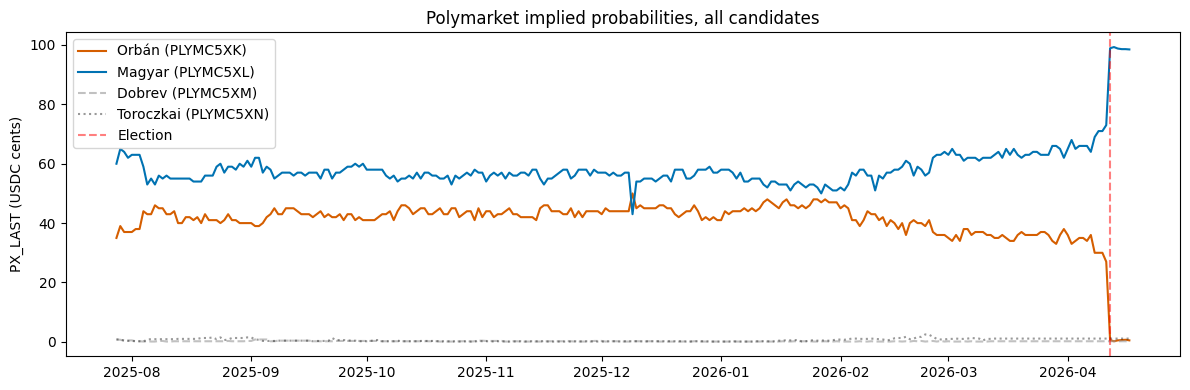

spread (Orbán - Magyar) at election day: -98.3


In [25]:

pm_long  = pd.read_csv('polymarket_panel.csv')
pm_wide  = pd.read_csv('polymarket_wide.csv')
pm = pm_wide.copy()
pm['date'] = pd.to_datetime(pm['date'])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pm['date'], pm['px_last_orban'], label='Orbán (PLYMC5XK)', color='#d55e00')
ax.plot(pm['date'], pm['px_last_magyar'], label='Magyar (PLYMC5XL)', color='#0072b2')
ax.plot(pm['date'], pm['px_last_dobrev'], label='Dobrev (PLYMC5XM)', color='#999999', alpha=0.6, linestyle='--')
ax.plot(pm['date'], pm['px_last_toroczkai'], label='Toroczkai (PLYMC5XN)', color='#000000', alpha=0.4, linestyle=':')
ax.axvline(pd.Timestamp('2026-04-12'), color='red', linestyle='--', alpha=0.5, label='Election')
ax.set_ylabel('PX_LAST (USDC cents)')
ax.set_title('Polymarket implied probabilities, all candidates')
ax.legend(loc='upper left')
fig.tight_layout()

plt.show()

print('spread (Orbán - Magyar) at election day:', pm.loc[pm.date == '2026-04-12', 'fidesz_tisza_spread'].iloc[0])

In [26]:
sent = pd.read_csv('sentiment_doc.csv')
corpus = pd.read_csv('corpus_master.csv')
df = corpus.merge(sent, on='doc_id', how='inner')
df['date'] = pd.to_datetime(df['date'])
print(f'merged: {df.shape}')
print(df.groupby('source')[['score_a','score_b','score_ensemble']].mean().round(3))

merged: (1345, 23)
              score_a  score_b  score_ensemble
source                                        
kormanyinfo     0.051    0.050           0.051
lazarinfo       0.041   -0.077          -0.018
magyar_peter    0.072    0.057           0.065
origo           0.028   -0.093          -0.033
telex          -0.059   -0.275          -0.167


In [27]:
t2 = (df.groupby('source')
        .agg(n=('doc_id','size'),
             mean_score=('score_ensemble','mean'),
             std_score=('score_ensemble','std'),
             share_pos=('score_ensemble', lambda x: (x>0.1).mean()),
             share_neg=('score_ensemble', lambda x: (x<-0.1).mean()),
             agreement_a_b=('score_ensemble', lambda x: float('nan'))  # filled below
        ).round(3).reset_index())
# True agreement: corr(score_a, score_b) at sign level
for src, g in df.groupby('source'):
    if len(g) < 5: continue
    sign_agree = ((np.sign(g['score_a']) == np.sign(g['score_b']))).mean()
    t2.loc[t2['source']==src, 'agreement_a_b'] = round(float(sign_agree), 3)
t2.to_csv('T2_sentiment_summary.csv')
t2

,source,n,mean_score,std_score,share_pos,share_neg,agreement_a_b
0,kormanyinfo,21,0.051,0.129,0.476,0.095,0.667
1,lazarinfo,49,-0.018,0.087,0.082,0.163,0.449
2,magyar_peter,104,0.065,0.108,0.346,0.048,0.606
3,origo,476,-0.033,0.278,0.290,0.466,0.721
4,telex,695,-0.167,0.177,0.075,0.658,0.800


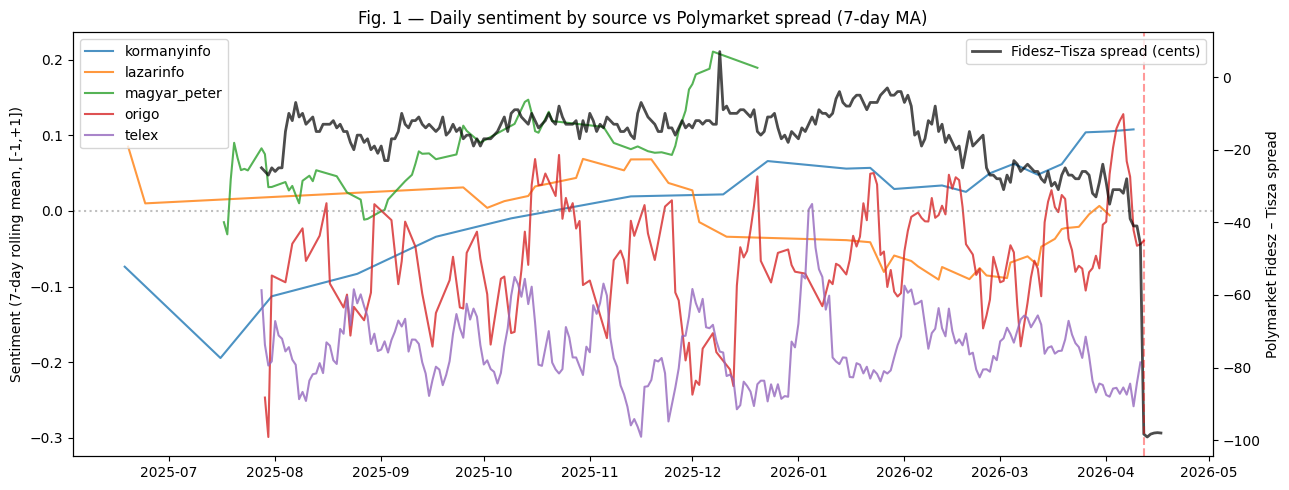

In [28]:
pm = pd.read_csv('polymarket_wide.csv'); pm['date'] = pd.to_datetime(pm['date'])

# Daily mean ensemble sentiment, weighted by n_words_clean
d = df.copy()
d['w'] = d['n_words_clean'].clip(lower=1); d['wv'] = d['w'] * d['score_ensemble']
daily = (d.groupby(['date','source']).agg(score=('wv','sum'), w=('w','sum'))
           .assign(score=lambda x: x['score']/x['w']).reset_index())

fig, ax1 = plt.subplots(figsize=(13,5))
for src, g in daily.groupby('source'):
    g = g.sort_values('date')
    ax1.plot(g['date'], g['score'].rolling(7, min_periods=1).mean(), label=src, alpha=0.8)
ax1.set_ylabel('Sentiment (7-day rolling mean, [-1,+1])')
ax1.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax1.legend(loc='upper left')
ax2 = ax1.twinx()
ax2.plot(pm['date'], pm['fidesz_tisza_spread'], color='black', linewidth=2, alpha=0.7, label='Fidesz–Tisza spread (cents)')
ax2.set_ylabel('Polymarket Fidesz – Tisza spread')
ax2.axvline(pd.Timestamp("2026-04-12"), color='red', linestyle='--', alpha=0.4)
ax2.legend(loc='upper right')
plt.title('Fig. 1 — Daily sentiment by source vs Polymarket spread (7-day MA)')
fig.tight_layout()

plt.show()